In [1]:
#LA API QUE SE REGISTRO SON LOS DATOS BASICOS DE LOS JUGADORES PARTICIPANTES
import requests
import pandas as pd

#SE HACE EL LLAMADO DE LA API DESDE UN APARTADO "SEGURO" COMO LO ES ESPN
base_url = "https://site.api.espn.com"
endpoint = "/apis/site/v2/sports/golf/pga/scoreboard?dates=20260823"
response = requests.get(base_url + endpoint)
print(response.status_code) # rectificamos que la aprobacion de la api fue la correcta 
data = response.json() # Convertimos la lectura a JSON para poder emepzar a interpretar 

print(data.keys()) # Miramos todo lo relacionado a lo que contiene el dataset

# ====================== EVENTO ======================================
#NOS ASEGURAMOS DEL TORNEO TRATADO - ESTE TORNEO TIENE BUENAS METRICAS Y OCURRIO HACE POCO
assert data["events"], "No hay eventos disponibles en la API en este momento" # Nos aseguramos de que haya al menos un torneo antes de indexar
evento = data["events"][0] # Ingreso al primer evento que se registro
print(evento["name"])# Tengo el nombre del evento
evento_id = evento["id"]
print("ID del torneo:", evento_id)
competicion = evento["competitions"][0]
jugador = competicion["competitors"]
# ================== CREACION DATAFRAME ============================
datos = []

for jugadores in jugador:

    nombre = jugadores["athlete"]["displayName"]

    # Score acumulado del jugador
    score = jugadores.get("score")

    # Posición
    posicion = jugadores.get("order")

    # Resultados por ronda
    linescores = jugadores.get("linescores", [])

    #Temporada
    season = evento["season"]["year"]

    ronda1 = linescores[0].get("value") if len(linescores) > 0 else None
    ronda2 = linescores[1].get("value") if len(linescores) > 1 else None
    ronda3 = linescores[2].get("value") if len(linescores) > 2 else None
    ronda4 = linescores[3].get("value") if len(linescores) > 3 else None


    datos.append(
        {
            "jugador": nombre,
            "posicion": posicion,
            "score": score,
            "ronda1": ronda1,
            "ronda2": ronda2,
            "ronda3": ronda3,
            "ronda4": ronda4,
            "Temporada" :season,
        }
    )


df = pd.DataFrame(datos)
df['score'] = df['score'].str.replace('E', '0')
df['ronda3'] = df['ronda3'].astype(int)
df['ronda2'] = df['ronda2'].astype(int)
df['ronda1'] = df['ronda1'].astype(int)
df['ronda4'] = df['ronda4'].astype(int)
df['score'] = df['score'].astype(int)
df

df.to_csv("BMW_respaldo.csv", index=False)

200
dict_keys(['leagues', 'season', 'day', 'events', 'provider'])
BMW Championship
ID del torneo: 401811963


In [2]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

col__pga = [
    "posicion",
    "score",
    "ronda1",
    "ronda2",
    "ronda3",
    "ronda4",
]

data_pga = df[col__pga].copy()
print(data_pga.head())


scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_pga)
display(data_scaled)

pd.DataFrame(data_scaled,columns=data_pga.columns)

pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_scaled)
data_pca

   posicion  score  ronda1  ronda2  ronda3  ronda4
0         1    -17      64      64      65      70
1         2    -14      67      65      66      68
2         3    -13      64      69      65      69
3         4    -12      68      65      67      68
4         5    -12      64      67      68      69


array([[-1.69774938, -2.66067467, -1.72949049, -1.59699214, -1.64918191,
         0.22249708],
       [-1.62845348, -2.01696305, -0.57649683, -1.21124525, -1.26205001,
        -0.66749124],
       [-1.55915759, -1.80239252, -1.72949049,  0.33174233, -1.64918191,
        -0.22249708],
       [-1.4898617 , -1.58782198, -0.19216561, -1.21124525, -0.8749181 ,
        -0.66749124],
       [-1.4205658 , -1.58782198, -1.72949049, -0.43975146, -0.4877862 ,
        -0.22249708],
       [-1.35126991, -1.58782198, -1.72949049, -1.21124525,  0.28647761,
        -0.22249708],
       [-1.28197402, -1.1586809 , -0.19216561,  0.33174233, -0.4877862 ,
        -2.00247372],
       [-1.21267813, -1.1586809 , -0.57649683, -0.82549835, -0.10065429,
        -0.66749124],
       [-1.14338223, -0.94411037, -0.96082805,  1.48898301, -1.26205001,
        -1.1124854 ],
       [-1.07408634, -0.72953983,  0.19216561, -1.21124525, -0.10065429,
        -0.22249708],
       [-1.00479045, -0.72953983, -0.57649683, -1.

array([[-3.92855439, -1.31688064],
       [-3.12725865, -0.68934673],
       [-2.81472243, -0.55055181],
       [-2.58979739, -0.5008825 ],
       [-2.63753285,  0.09474586],
       [-2.70130558,  0.45768728],
       [-1.94796105,  0.96941982],
       [-2.03033377,  0.25644167],
       [-1.56184975,  0.36831344],
       [-1.45977314, -0.29412904],
       [-1.52312101, -0.44997612],
       [-1.04141215, -0.59669336],
       [-1.12224699,  0.73796995],
       [-1.1266458 ,  0.01153022],
       [-0.95905955, -0.50914572],
       [-0.71894693,  0.81078754],
       [-0.73400786,  1.18616945],
       [-0.50747255,  0.09490087],
       [-0.60050738,  0.48374436],
       [-0.54638199, -0.2944995 ],
       [-0.62039198,  0.65147505],
       [-0.14550796,  0.89344656],
       [-0.31694154,  1.81454014],
       [-0.35785216,  2.02147974],
       [-0.35798886,  0.06311864],
       [ 0.28308023, -0.30486614],
       [ 0.13792118,  0.26588124],
       [ 0.5348313 ,  0.52131433],
       [ 0.65711818,

In [3]:
pca.explained_variance_ratio_

array([0.47479661, 0.20373309])

In [4]:
pca.components_

array([[ 0.58409968,  0.58895661,  0.33734055,  0.32725625,  0.19144345,
         0.23326333],
       [-0.0125022 ,  0.06161423, -0.27644453,  0.22838321,  0.69744187,
        -0.61728579]])

Text(0, 0.5, 'Componente principal 2')

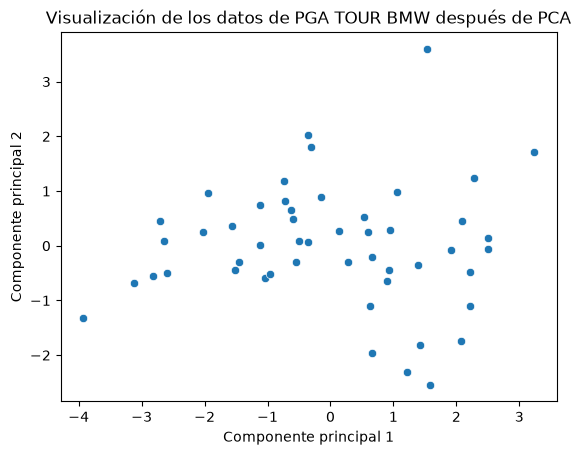

In [5]:
import seaborn as sns
sns.scatterplot(x=data_pca[:, 0], y=data_pca[:, 1])
plt.title("Visualización de los datos de PGA TOUR BMW después de PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

Text(0, 0.5, 'Componente principal 2')

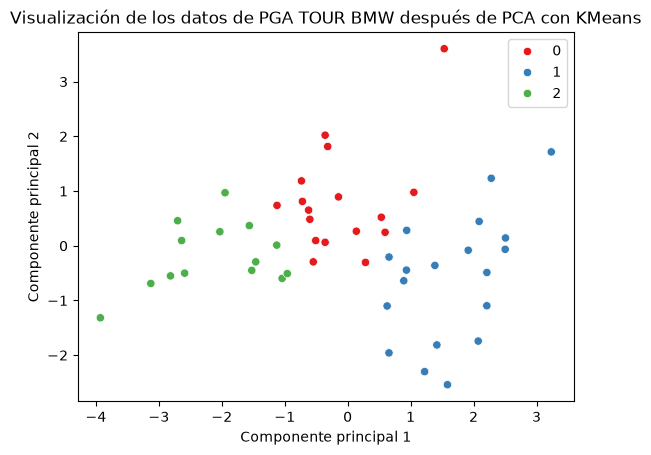

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(data_pca)

sns.scatterplot(x=data_pca[:, 0], y=data_pca[:, 1], hue=kmeans.labels_, palette='Set1')
plt.title("Visualización de los datos de PGA TOUR BMW después de PCA con KMeans")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

In [7]:
kmeans.labels_

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1], dtype=int32)

In [8]:
data_clusters = pd.concat(
    [data_pga.reset_index(drop=True), pd.DataFrame(kmeans.labels_, columns=["Cluster"])],
    axis=1
)

display(data_clusters.head(50))

,posicion,score,ronda1,ronda2,ronda3,ronda4,Cluster
0,1,-17,64,64,65,70,2
1,2,-14,67,65,66,68,2
2,3,-13,64,69,65,69,2
3,4,-12,68,65,67,68,2
4,5,-12,64,67,68,69,2
5,6,-12,64,65,70,69,2
6,7,-10,68,69,68,65,2
7,8,-10,67,66,69,68,2
8,9,-9,66,72,66,67,2
9,10,-8,69,65,69,69,2


In [9]:
data_clusters.dtypes

data_clusters['score'] = data_clusters['score'].astype(float)

data_clusters.dtypes

posicion      int64
score       float64
ronda1        int64
ronda2        int64
ronda3        int64
ronda4        int64
Cluster       int32
dtype: object

In [10]:
data_clusters.groupby('Cluster').mean()

,posicion,score,ronda1,ronda2,ronda3,ronda4
Cluster,,,,,,
0,24.058824,-4.588235,68.058824,68.235294,70.823529,68.294118
1,39.947368,-0.315789,70.315789,69.210526,69.000000,71.157895
2,7.642857,-10.428571,66.571429,66.571429,67.714286,68.714286


<Axes: ylabel='Cluster'>

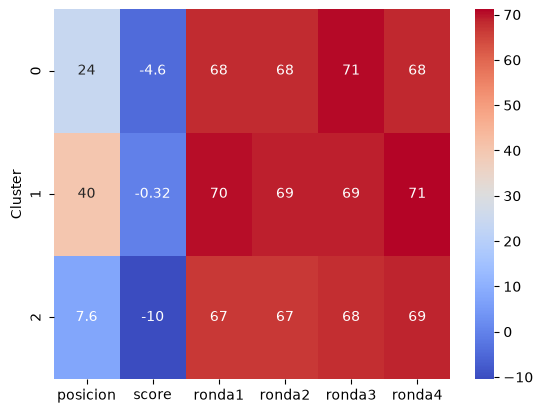

In [11]:
sns.heatmap(data_clusters.groupby('Cluster').mean(), annot=True, cmap='coolwarm')

In [12]:
data_clusters.to_csv("BMW.csv", index=False)